# 1. Import Libraries

In [ ]:
import tensorflow as tf 
from tensorflow.keras import layers, models, datasets 
import matplotlib.pyplot as plt 
import numpy as np 
import tensorflow_datasets as tfds

I0000 00:00:1779379380.782491    1475 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1779379385.770354    1475 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


# 2. Downloading and preparing the dataset

In [ ]:
(x_train, y_train), (x_test, y_test) = datasets.cifar100.load_data(label_mode='fine')

In [ ]:
x_train

array([[[[255, 255, 255],
         [255, 255, 255],
         [255, 255, 255],
         ...,
         [195, 205, 193],
         [212, 224, 204],
         [182, 194, 167]],

        [[255, 255, 255],
         [254, 254, 254],
         [254, 254, 254],
         ...,
         [170, 176, 150],
         [161, 168, 130],
         [146, 154, 113]],

        [[255, 255, 255],
         [254, 254, 254],
         [255, 255, 255],
         ...,
         [189, 199, 169],
         [166, 178, 130],
         [121, 133,  87]],

        ...,

        [[148, 185,  79],
         [142, 182,  57],
         [140, 179,  60],
         ...,
         [ 30,  17,   1],
         [ 65,  62,  15],
         [ 76,  77,  20]],

        [[122, 157,  66],
         [120, 155,  58],
         [126, 160,  71],
         ...,
         [ 22,  16,   3],
         [ 97, 112,  56],
         [141, 161,  87]],

        [[ 87, 122,  41],
         [ 88, 122,  39],
         [101, 134,  56],
         ...,
         [ 34,  36,  10],
        

In [ ]:
x_train.shape

(50000, 32, 32, 3)

In [ ]:
x_test.shape

(10000, 32, 32, 3)

In [ ]:
y_train

array([[19],
       [29],
       [ 0],
       ...,
       [ 3],
       [ 7],
       [73]], shape=(50000, 1))

## Các loại trong dataset 

In [ ]:
ds_info = tfds.builder('cifar100').info
cifar100_classes = ds_info.features['label'].names
cifar100_classes = [
    'apple',          # 0
    'aquarium_fish',  # 1
    'baby',           # 2
    'bear',           # 3
    'beaver',         # 4
    'bed',            # 5
    'bee',            # 6
    'beetle',         # 7
    'bicycle',        # 8
    'bottle',         # 9
    'bowl',           # 10
    'boy',            # 11
    'bridge',         # 12
    'bus',            # 13
    'butterfly',      # 14
    'camel',          # 15
    'can',            # 16
    'castle',         # 17
    'caterpillar',    # 18
    'cattle',         # 19
    'chair',          # 20
    'chimpanzee',     # 21
    'clock',          # 22
    'cloud',          # 23
    'cockroach',      # 24
    'couch',          # 25
    'crab',           # 26
    'crocodile',      # 27
    'cup',            # 28
    'dinosaur',       # 29
    'dolphin',        # 30
    'elephant',       # 31
    'flatfish',       # 32
    'forest',         # 33
    'fox',            # 34
    'girl',           # 35
    'hamster',        # 36
    'house',          # 37
    'kangaroo',       # 38
    'keyboard',       # 39
    'lamp',           # 40
    'lawn_mower',     # 41
    'leopard',        # 42
    'lion',           # 43
    'lizard',         # 44
    'lobster',        # 45
    'man',            # 46
    'maple_tree',     # 47
    'motorcycle',     # 48
    'mountain',       # 49
    'mouse',          # 50
    'mushroom',       # 51
    'oak_tree',       # 52
    'orange',         # 53
    'orchid',         # 54
    'otter',          # 55
    'palm_tree',      # 56
    'pear',           # 57
    'pickup_truck',   # 58
    'pine_tree',      # 59
    'plain',          # 60
    'plate',          # 61
    'poppy',          # 62
    'porcupine',      # 63
    'possum',         # 64
    'rabbit',         # 65
    'raccoon',        # 66
    'ray',            # 67
    'road',           # 68
    'rocket',         # 69
    'rose',           # 70
    'sea',            # 71
    'seal',           # 72
    'shark',          # 73
    'shrew',          # 74
    'skunk',          # 75
    'skyscraper',     # 76
    'snail',          # 77
    'snake',          # 78
    'spider',         # 79
    'squirrel',       # 80
    'streetcar',      # 81
    'sunflower',      # 82
    'sweet_pepper',   # 83
    'table',          # 84
    'tank',           # 85
    'telephone',      # 86
    'television',     # 87
    'tiger',          # 88
    'tractor',        # 89
    'train',          # 90
    'trout',          # 91
    'tulip',          # 92
    'turtle',         # 93
    'wardrobe',       # 94
    'whale',          # 95
    'willow_tree',    # 96
    'wolf',           # 97
    'woman',          # 98
    'worm'            # 99
]

In [ ]:
superclasses = [
    "aquatic_mammals",
    "fish",
    "flowers",
    "food_containers",
    "fruit_and_vegetables",
    "household_electrical_devices",
    "household_furniture",
    "insects",
    "large_carnivores",
    "large_man-made_outdoor_things",
    "large_natural_outdoor_scenes",
    "large_omnivores_and_herbivores",
    "medium_mammals",
    "non-insect_invertebrates",
    "people",
    "reptiles",
    "small_mammals",
    "trees",
    "vehicles_1",
    "vehicles_2"
]

# 3. Normalize 

In [ ]:
x_train, x_test = x_train/255.0, x_test / 255.0

In [ ]:
x_train 

array([[[[1.        , 1.        , 1.        ],
         [1.        , 1.        , 1.        ],
         [1.        , 1.        , 1.        ],
         ...,
         [0.76470588, 0.80392157, 0.75686275],
         [0.83137255, 0.87843137, 0.8       ],
         [0.71372549, 0.76078431, 0.65490196]],

        [[1.        , 1.        , 1.        ],
         [0.99607843, 0.99607843, 0.99607843],
         [0.99607843, 0.99607843, 0.99607843],
         ...,
         [0.66666667, 0.69019608, 0.58823529],
         [0.63137255, 0.65882353, 0.50980392],
         [0.57254902, 0.60392157, 0.44313725]],

        [[1.        , 1.        , 1.        ],
         [0.99607843, 0.99607843, 0.99607843],
         [1.        , 1.        , 1.        ],
         ...,
         [0.74117647, 0.78039216, 0.6627451 ],
         [0.65098039, 0.69803922, 0.50980392],
         [0.4745098 , 0.52156863, 0.34117647]],

        ...,

        [[0.58039216, 0.7254902 , 0.30980392],
         [0.55686275, 0.71372549, 0.22352941]

In [ ]:
x_test

array([[[[0.78039216, 0.84313725, 0.97647059],
         [0.76862745, 0.82745098, 0.95686275],
         [0.76470588, 0.82352941, 0.95294118],
         ...,
         [0.84705882, 0.90588235, 0.98039216],
         [0.85098039, 0.90588235, 0.98039216],
         [0.87843137, 0.91764706, 0.98823529]],

        [[0.77254902, 0.82352941, 0.9372549 ],
         [0.76470588, 0.81568627, 0.93333333],
         [0.76470588, 0.82352941, 0.94117647],
         ...,
         [0.90588235, 0.95294118, 0.98039216],
         [0.91372549, 0.95294118, 0.98039216],
         [0.94509804, 0.96078431, 0.99215686]],

        [[0.87058824, 0.88627451, 0.96470588],
         [0.83529412, 0.8627451 , 0.94901961],
         [0.81960784, 0.85882353, 0.95294118],
         ...,
         [0.95294118, 0.98039216, 0.98431373],
         [0.95686275, 0.97647059, 0.98431373],
         [0.98039216, 0.98039216, 0.99215686]],

        ...,

        [[0.28235294, 0.28627451, 0.38823529],
         [0.27843137, 0.29019608, 0.4       ]

In [ ]:
np.where(y_train.flatten() == 1)

(array([     19,     129,     200, ..., 4999703, 4999807, 4999973],
       shape=(50000,)),)

In [ ]:
y_train.flatten()

array([0., 0., 0., ..., 0., 0., 0.], shape=(5000000,))

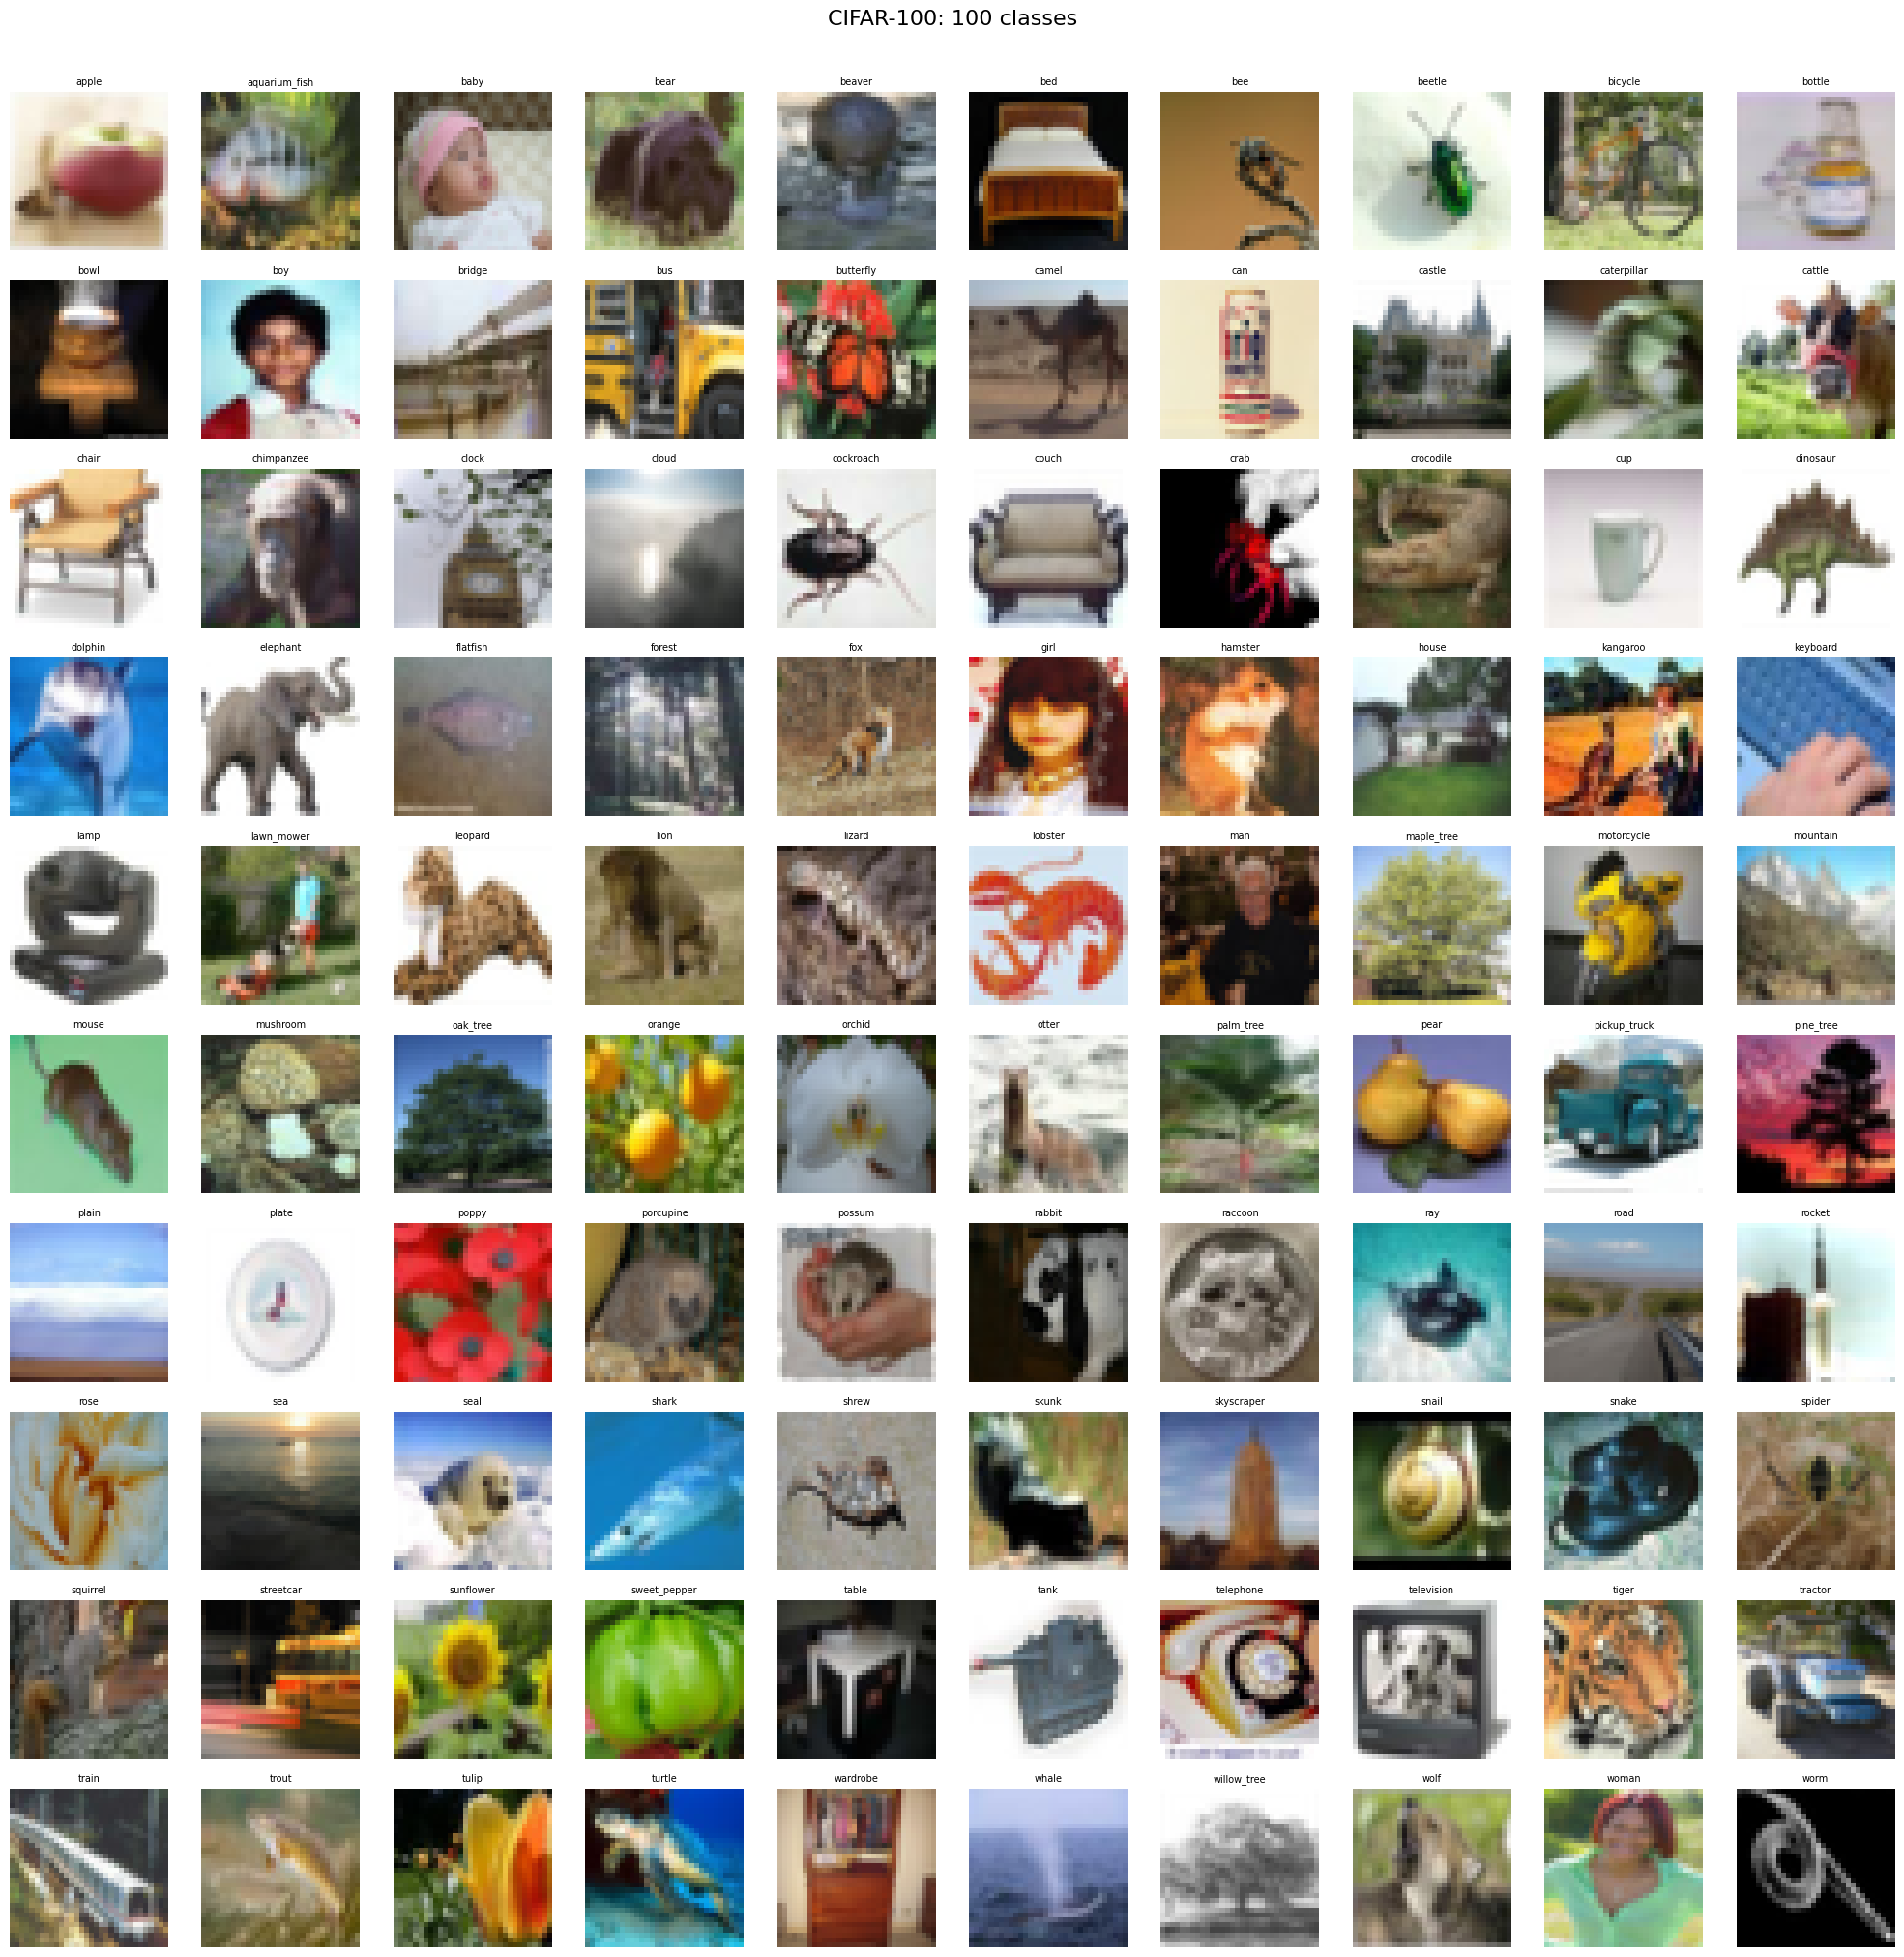

In [ ]:
fig, axes = plt.subplots(10, 10, figsize=(20, 20))
for class_idx in range(100):
    img_idx = np.where(y_train.flatten() == class_idx)[0][0]
    img=x_train[img_idx]
     
    row, col = class_idx//10, class_idx%10 
    axes[row, col].imshow(img)
    axes[row, col].set_title(cifar100_classes[class_idx], fontsize=7)
    axes[row, col].axis('off')
plt.suptitle("CIFAR-100: 100 classes", fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig("../images/cifar100_all_classes.png", dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
num_classes=100
y_train = tf.keras.utils.to_categorical(y_train, num_classes)
y_test = tf.keras.utils.to_categorical(y_test, num_classes)

In [ ]:
y_train 

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(50000, 100))